# 05 Sentiment: ดวงของราศีไหน/เว็บไหนเป็นบวกกว่ากัน

**เจ้าของ:** Member 6 · **ข้อมูล:** `data/processed/horoscopes.csv`

**คำถาม (วัตถุประสงค์ข้อ 3):** เปรียบเทียบ sentiment (บวก / กลาง / ลบ) ระหว่าง**ราศี**และระหว่าง**เว็บ**

**โมเดล:** [`phoner45/wangchan-sentiment-thai-text-model`](https://huggingface.co/phoner45/wangchan-sentiment-thai-text-model)
คือ WangchanBERTa ที่ fine-tune แล้วด้วยรีวิว Wongnai และข้อความโซเชียล Wisesight (pre-trained, เราไม่ได้เทรนเพิ่ม)

### ปัญหาที่เจอก่อนเริ่ม และวิธีแก้ (อ่านก่อนดูผล)
1. **โมเดลไม่เคยเห็นภาษาดวง:** ถ้าใช้ป้ายที่โมเดลทายตรงๆ **97.7% ของข้อความจะได้ "neu"**
   ประโยคบวกอย่าง "การเงินคล่องตัวดี มีรายได้เข้ามาต่อเนื่อง" ก็ได้ neu เพราะ "บวก" ในรีวิวคือ "อร่อยมาก ชอบมาก"
   → **ใช้คะแนนต่อเนื่อง `score = P(pos) − P(neg)`** (−1 ถึง +1) แทนป้าย เพราะคะแนน**เรียงลำดับ**ได้ถูกต้อง (ดูส่วนที่ 2)
2. **โมเดลเทรนกับข้อความสั้น** แต่คำทำนายยาว และมีทั้งเรื่องดีและร้ายปนกัน
   → **ตัดแต่ละคำทำนายเป็นช่วงสั้นๆ** (ประมาณ 1–3 ประโยค, ≤ 64 token) ให้คะแนนทีละช่วง แล้ว**เฉลี่ย**เป็นคะแนนของข้อความ
3. **ต้องรู้ว่าโมเดลเชื่อถือได้แค่ไหน** → ทำ**ชุดตรวจสอบ** 40 ช่วงจากข้อมูลจริง ติดป้ายด้วยคนโดยไม่เห็นคะแนน
   (`data/processed/sentiment_validation.csv` ทีมเพิ่มหรือแก้ป้ายได้ แล้วรันโน้ตบุ๊กใหม่)

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import kruskal, spearmanr

warnings.filterwarnings("ignore")
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from src.thai_text import THAI_FONT, ZODIAC_TH, clean_text

FIG_DIR = PROJECT_ROOT / "outputs" / "figures"
CACHE = PROJECT_ROOT / "outputs" / "05_segment_scores.csv"    # model scores per segment (about 14 min to compute)
RECOMPUTE = False
MODEL_ID = "phoner45/wangchan-sentiment-thai-text-model"
font_manager.fontManager.addfont(THAI_FONT)
THAI_FONT_NAME = font_manager.FontProperties(fname=THAI_FONT).get_name()
plt.rcParams.update({
    "font.family": THAI_FONT_NAME, "font.size": 11,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "normal",
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "savefig.dpi": 200, "savefig.bbox": "tight",
})
SITES = ["marumura", "sanook", "thairath", "kapook"]
SITE_COLORS = {"marumura": "#2a78d6", "sanook": "#eb6834", "thairath": "#1baf7a", "kapook": "#eda100"}
SIGNS = ["Aries", "Taurus", "Gemini", "Cancer", "Leo", "Virgo", "Libra", "Scorpio",
         "Sagittarius", "Capricorn", "Aquarius", "Pisces"]
SIGN_TH = {en: th for th, en in ZODIAC_TH.items()}
# Diverging colors for sentiment: blue = positive, grey = neutral, red = negative
SENT_COLORS = {"pos": "#256abf", "neu": "#c3c2b7", "neg": "#e34948"}
DIVERGING = LinearSegmentedColormap.from_list("div", ["#e34948", "#f3b2b1", "#f0efec", "#9ec5f4", "#256abf"])

## 1) ตัดเป็นช่วงสั้นๆ และให้คะแนนด้วยโมเดล

In [2]:
df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "horoscopes.csv")

if CACHE.exists() and not RECOMPUTE:
    seg = pd.read_csv(CACHE)
else:
    import torch
    from transformers import AutoModelForSequenceClassification, AutoTokenizer
    tok = AutoTokenizer.from_pretrained(MODEL_ID)
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_ID).eval()

    def segments(text, min_chars=40, max_tokens=64):
        """Cut a text into short pieces (Thai spaces separate phrases); at least 40 characters each."""
        segs, cur = [], ""
        for piece in clean_text(text, remove_signs=False).split():
            cand = (cur + " " + piece).strip()
            if len(cur) >= min_chars and len(tok(cand)["input_ids"]) > max_tokens:
                segs.append(cur)
                cur = piece
            else:
                cur = cand
        if cur:
            if segs and len(cur) < min_chars:
                segs[-1] += " " + cur
            else:
                segs.append(cur)
        return segs

    rows = [(i, j, s) for i, t in enumerate(df["text"]) for j, s in enumerate(segments(t))]
    seg = pd.DataFrame(rows, columns=["row", "seg_no", "segment"])
    probs = []
    with torch.no_grad():
        for k in range(0, len(seg), 32):
            enc = tok(seg["segment"].iloc[k:k + 32].tolist(), padding=True, truncation=True,
                      max_length=128, return_tensors="pt")
            probs.append(torch.softmax(model(**enc).logits, dim=-1).numpy())
    P = np.vstack(probs)
    for idx, name in model.config.id2label.items():
        seg["P_" + name] = P[:, int(idx)]
    seg["score"] = seg["P_pos"] - seg["P_neg"]
    seg.to_csv(CACHE, index=False)

seg["model_label"] = seg[["P_pos", "P_neu", "P_neg"]].idxmax(axis=1).str[2:]
print(f"{len(seg)} segments ({len(seg) / len(df):.1f} per text, {seg['segment'].str.len().mean():.0f} characters each)")
print("label the model would give (argmax):", seg["model_label"].value_counts(normalize=True).round(3).to_dict())

4278 segments (3.5 per text, 242 characters each)
label the model would give (argmax): {'neu': 0.977, 'neg': 0.014, 'pos': 0.008}


## 2) ตรวจสอบโมเดลกับชุดที่คนติดป้าย

ชุดตรวจสอบมี 40 ช่วง สุ่มมาจากทุกช่วงคะแนน (5 ช่วง ช่วงละ 8) แล้ว**ติดป้ายโดยไม่เห็นคะแนน**
กติกา: **pos** = ส่วนใหญ่เป็นเรื่องดี, **neg** = ส่วนใหญ่เป็นคำเตือนหรือเรื่องร้าย, **neu** = ข้อมูลหรือคำแนะนำกลางๆ **หรือมีทั้งดีและร้ายพอๆ กัน**

ตัวเลขที่ดู:
- **AUC**: โอกาสที่ข้อความ pos ได้คะแนนสูงกว่าข้อความ neg (0.5 = สุ่ม, 1 = แยกได้สมบูรณ์)
- **Spearman**: คะแนนเรียงลำดับสอดคล้องกับป้าย neg < neu < pos แค่ไหน
- **เกณฑ์ τ** สำหรับแปลงคะแนนเป็น 3 ป้าย (score > τ → pos, score < −τ → neg) เลือกค่าที่ตรงกับคนมากที่สุด แล้ววัดแบบ leave-one-out ไม่ให้ประเมินดีเกินจริง

In [3]:
val = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "sentiment_validation.csv")
val = val.merge(seg[["row", "seg_no", "score", "model_label"]], on=["row", "seg_no"], how="left")
s, y = val["score"].to_numpy(), val["label"].to_numpy()

def auc(a, b):
    return np.mean([x > z for x in a for z in b])

def accuracy(tau, idx):
    pred = np.where(s[idx] > tau, "pos", np.where(s[idx] < -tau, "neg", "neu"))
    return (pred == y[idx]).mean()

grid = np.round(np.arange(0.005, 0.2, 0.005), 3)
TAU = float(max(grid, key=lambda t: accuracy(t, np.arange(len(s)))))
loo = [accuracy(max(grid, key=lambda t: accuracy(t, np.delete(np.arange(len(s)), i))), np.array([i]))
       for i in range(len(s))]
rho, p_rho = spearmanr(pd.Series(y).map({"neg": -1, "neu": 0, "pos": 1}), s)
validation = pd.Series({
    "จำนวน (pos / neu / neg)": f"{(y == 'pos').sum()} / {(y == 'neu').sum()} / {(y == 'neg').sum()}",
    "AUC pos vs neg": round(auc(s[y == "pos"], s[y == "neg"]), 3),
    "AUC pos vs neu": round(auc(s[y == "pos"], s[y == "neu"]), 3),
    "AUC neu vs neg": round(auc(s[y == "neu"], s[y == "neg"]), 3),
    "Spearman (p)": f"{rho:.2f} ({p_rho:.1e})",
    "ป้ายของโมเดลตรงกับคน (argmax)": f"{(val['model_label'] == val['label']).mean():.1%}",
    "τ ที่เลือก": TAU,
    "ความแม่น 3 ป้ายด้วย τ (ข้อมูลชุดเดียวกัน)": f"{accuracy(TAU, np.arange(len(s))):.1%}",
    "ความแม่น 3 ป้าย leave-one-out": f"{np.mean(loo):.1%}",
    "baseline: ทาย neu ทุกข้อ": f"{(y == 'neu').mean():.1%}",
})
display(validation.to_frame("ค่า"))
val.groupby("label")["score"].describe()[["count", "mean", "min", "50%", "max"]].reindex(["neg", "neu", "pos"]).round(3)

,ค่า
จำนวน (pos / neu / neg),13 / 16 / 11
AUC pos vs neg,0.944
AUC pos vs neu,0.76
AUC neu vs neg,0.835
Spearman (p),0.67 (2.2e-06)
ป้ายของโมเดลตรงกับคน (argmax),37.5%
τ ที่เลือก,0.07
ความแม่น 3 ป้ายด้วย τ (ข้อมูลชุดเดียวกัน),67.5%
ความแม่น 3 ป้าย leave-one-out,47.5%
baseline: ทาย neu ทุกข้อ,40.0%


,count,mean,min,50%,max
label,,,,,
neg,11.0,-0.117,-0.319,-0.073,0.014
neu,16.0,-0.022,-0.591,0.000,0.105
pos,13.0,0.122,-0.115,0.079,0.425


**จากผลตรวจสอบ พบว่า**
- **ป้ายที่โมเดลทายตรงกับคนแค่ 37.5%** ต่ำกว่าการทาย "neu" ทุกข้อ (40%) เพราะโมเดลตอบ neu เกือบทุกช่วง จึงใช้ป้ายของโมเดลตรงๆ ไม่ได้
- **แต่คะแนน `score` เรียงลำดับได้ดี:** ช่วงที่คนบอกว่า pos ได้คะแนนสูงกว่าช่วง neg ถึง 94% ของคู่ (AUC = 0.94) และ Spearman = 0.67 (p < 0.001)
  ค่าเฉลี่ย: neg −0.12 < neu −0.02 < pos +0.12 เรียงถูกทุกกลุ่ม
- **ถ้าแปลงคะแนนเป็น 3 ป้ายด้วยเกณฑ์ τ = 0.07** จะตรงกับคน 67.5% ในชุดเดียวกัน แต่ถ้าวัดแบบ leave-one-out ได้แค่ **47.5%** (baseline 40%) แปลว่าการแบ่งเป็น 3 ป้าย**ยังไม่น่าเชื่อถือนัก**

**สรุปวิธีใช้:** ใช้**คะแนนเฉลี่ย** เป็นตัววัดหลักในการเปรียบเทียบ ส่วน**สัดส่วน บวก/กลาง/ลบ** ใช้ดูภาพรวมได้ แต่ไม่ควรอ่านตัวเลขเปอร์เซ็นต์ละเอียดเกินไป
*ข้อจำกัด:* ชุดตรวจสอบมีแค่ 40 ช่วง ติดป้ายโดยคนเดียว (Claude) ถ้าทีมมีเวลา ควรให้สมาชิก 2 คนติดป้ายแยกกันในไฟล์ `sentiment_validation.csv` แล้ววัดความตรงกันระหว่างคน (inter-annotator agreement)

## 3) คะแนนของแต่ละคำทำนาย

In [4]:
# Text score = average of its segment scores, weighted by segment length
seg["chars"] = seg["segment"].str.len()
text_score = seg.groupby("row").apply(lambda g: np.average(g["score"], weights=g["chars"]))
df["score"] = text_score.reindex(range(len(df))).to_numpy()
df["label"] = np.where(df["score"] > TAU, "pos", np.where(df["score"] < -TAU, "neg", "neu"))

# How often does ONE horoscope contain both a clearly positive and a clearly negative part?
seg["seg_label"] = np.where(seg["score"] > TAU, "pos", np.where(seg["score"] < -TAU, "neg", "neu"))
mixed = seg.groupby("row")["seg_label"].agg(lambda x: ("pos" in set(x)) and ("neg" in set(x)))
df["has_pos_and_neg"] = mixed.reindex(range(len(df))).to_numpy()

site_table = df.groupby("source").agg(
    n=("score", "size"), mean_score=("score", "mean"), sd=("score", "std"),
    pos=("label", lambda x: (x == "pos").mean()), neu=("label", lambda x: (x == "neu").mean()),
    neg=("label", lambda x: (x == "neg").mean()), has_pos_and_neg=("has_pos_and_neg", "mean"),
).reindex(SITES)
site_table.round(3)

,n,mean_score,sd,pos,neu,neg,has_pos_and_neg
source,,,,,,,
marumura,312,0.037,0.174,0.426,0.369,0.205,0.135
sanook,309,-0.019,0.038,0.003,0.906,0.091,0.172
thairath,300,0.101,0.138,0.537,0.397,0.067,0.077
kapook,312,0.003,0.083,0.147,0.715,0.138,0.240


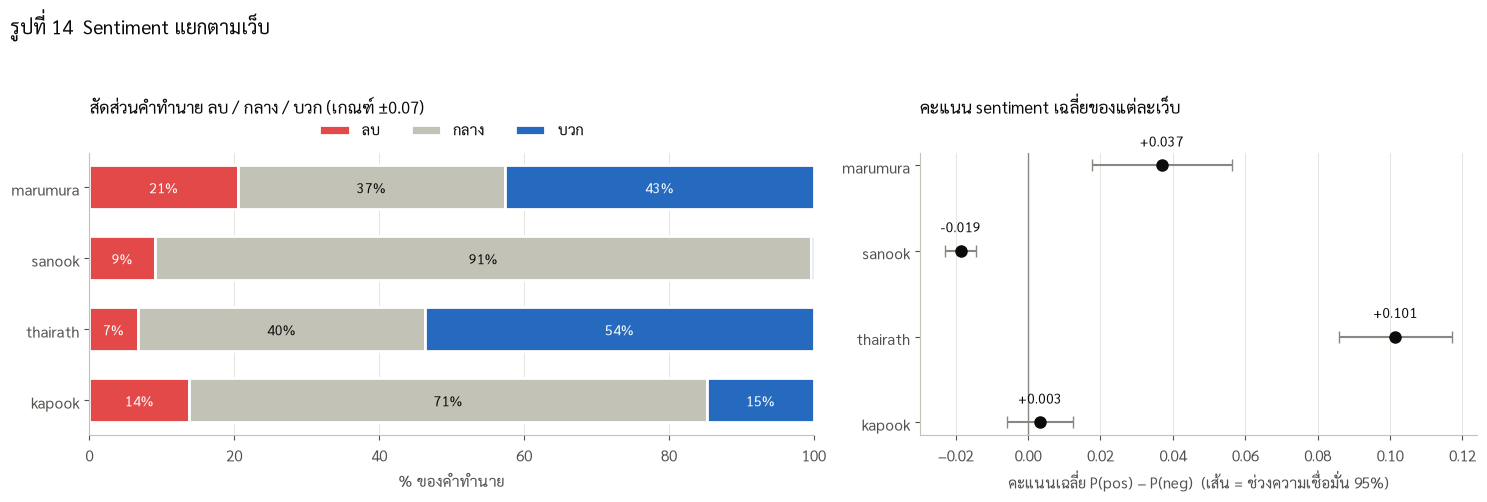

In [5]:
# Figure 14: sentiment by site. Left: share of negative / neutral / positive texts. Right: mean score with 95% CI
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
y_pos = np.arange(len(SITES))[::-1]
left = np.zeros(len(SITES))
for name, label in [("neg", "ลบ"), ("neu", "กลาง"), ("pos", "บวก")]:
    vals = site_table[name].to_numpy()
    ax1.barh(y_pos, vals * 100, left=left * 100, color=SENT_COLORS[name], edgecolor="white", linewidth=2,
             height=0.62, label=label)
    for k, (v, l) in enumerate(zip(vals, left)):
        if v >= 0.06:
            ax1.text((l + v / 2) * 100, y_pos[k], f"{v:.0%}", ha="center", va="center", fontsize=10,
                     color="white" if name != "neu" else "#0b0b0b")
    left += vals
ax1.set_yticks(y_pos, SITES)
ax1.set_xlim(0, 100)
ax1.set_xlabel("% ของคำทำนาย")
ax1.grid(axis="y", visible=False)
ax1.legend(frameon=False, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0))
ax1.set_title(f"สัดส่วนคำทำนาย ลบ / กลาง / บวก (เกณฑ์ ±{TAU})", loc="left", pad=28)

ci = 1.96 * site_table["sd"] / np.sqrt(site_table["n"])
ax2.axvline(0, color="#898781", linewidth=1)
ax2.errorbar(site_table["mean_score"], y_pos, xerr=ci, fmt="o", color="#0b0b0b", ecolor="#898781",
             capsize=4, markersize=8)
for k, site in enumerate(SITES):
    ax2.text(site_table.loc[site, "mean_score"], y_pos[k] + 0.22, f"{site_table.loc[site, 'mean_score']:+.3f}",
             ha="center", fontsize=10)
ax2.set_yticks(y_pos, SITES)
ax2.set_xlabel("คะแนนเฉลี่ย P(pos) − P(neg)  (เส้น = ช่วงความเชื่อมั่น 95%)")
ax2.grid(axis="y", visible=False)
ax2.set_title("คะแนน sentiment เฉลี่ยของแต่ละเว็บ", loc="left", pad=28)
fig.suptitle("รูปที่ 14  Sentiment แยกตามเว็บ", x=0.01, ha="left", fontsize=14, y=1.04)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_sentiment_by_site.png")
plt.show()

**จากรูปที่ 14 พบว่า** sentiment ต่างกันชัดเจนตาม**เว็บ**
- **thairath บวกที่สุด** (คะแนนเฉลี่ย +0.10, คำทำนายบวก 54% ลบแค่ 7%) สอดคล้องกับ topic ใน 04 ที่เน้น "มีโอกาส รายได้ โชคลาภ"
- **marumura** เป็นบวกเล็กน้อย (+0.04) แต่**กระจายมากที่สุด** คือมีทั้งบวก (43%) และลบ (21%) เพราะภาษาพูดตรงๆ เช่น "การเงิน ไม่มี ไม่มี ไม่มี"
- **kapook** เกือบเป็นกลาง (+0.003, กลาง 71%)
- **sanook** เป็นกลาง/ลบเล็กน้อย (−0.02, **กลาง 91%**) เพราะเขียนเป็นทางการด้วยศัพท์โหราศาสตร์ และเต็มไปด้วยคำเตือน "ควรระวัง" ซึ่งโมเดลที่เทรนจากรีวิวมองว่าเป็นกลาง

ช่วงความเชื่อมั่น 95% ของแต่ละเว็บแทบไม่ซ้อนกัน แปลว่าความต่างระหว่างเว็บเป็นของจริง **"ใครเขียน" กำหนดว่าดวงจะดีหรือร้ายด้วย** ไม่ใช่แค่กำหนดคำที่ใช้

## 4) ราศีไหนได้ดวงดีที่สุด (ranking)

In [6]:
sign_table = df.groupby("zodiac").agg(n=("score", "size"), mean_score=("score", "mean"), sd=("score", "std"),
                                     pos=("label", lambda x: (x == "pos").mean()),
                                     neg=("label", lambda x: (x == "neg").mean())).reindex(SIGNS)
sign_site = df.pivot_table(index="zodiac", columns="source", values="score", aggfunc="mean").reindex(index=SIGNS, columns=SITES)

# Kruskal-Wallis: does the score differ between the 12 signs? (all sites together, then inside each site)
tests = {"ทุกเว็บรวม": kruskal(*[g["score"] for _, g in df.groupby("zodiac")]).pvalue}
for site in SITES:
    sub = df[df["source"] == site]
    tests[site] = kruskal(*[g["score"] for _, g in sub.groupby("zodiac")]).pvalue

# Effect size: share of the score's variance explained by a grouping (eta squared, 0 = none, 1 = all)
def eta_squared(data, col):
    grand = data["score"].mean()
    between = sum(len(g) * (g["score"].mean() - grand) ** 2 for _, g in data.groupby(col))
    return between / ((data["score"] - grand) ** 2).sum()

summary_tests = pd.DataFrame({
    "Kruskal-Wallis p (ราศีต่างกันไหม)": pd.Series(tests),
    "eta² ของราศี": pd.Series({"ทุกเว็บรวม": eta_squared(df, "zodiac"),
                                **{s: eta_squared(df[df["source"] == s], "zodiac") for s in SITES}}),
})
summary_tests["ผ่าน Bonferroni (p < 0.05/4)"] = summary_tests["Kruskal-Wallis p (ราศีต่างกันไหม)"] < 0.05 / 4
display(summary_tests.round(4))
print(f"ทุกเว็บรวม: เว็บอธิบายความแปรปรวนของคะแนนได้ {eta_squared(df, 'source'):.1%} ส่วนราศีอธิบายได้ {eta_squared(df, 'zodiac'):.1%}")
sign_table.sort_values("mean_score", ascending=False).round(3)

,Kruskal-Wallis p (ราศีต่างกันไหม),eta² ของราศี,ผ่าน Bonferroni (p < 0.05/4)
ทุกเว็บรวม,0.1979,0.0066,False
marumura,0.9317,0.0142,False
sanook,0.0000,0.1515,True
thairath,0.0390,0.0711,False
kapook,0.0107,0.0706,True


ทุกเว็บรวม: เว็บอธิบายความแปรปรวนของคะแนนได้ 12.4% ส่วนราศีอธิบายได้ 0.7%


,n,mean_score,sd,pos,neg
zodiac,,,,,
Sagittarius,103,0.052,0.124,0.330,0.107
Cancer,103,0.040,0.124,0.291,0.078
Libra,103,0.038,0.127,0.282,0.107
Aquarius,103,0.037,0.116,0.291,0.087
Gemini,102,0.035,0.114,0.304,0.137
Scorpio,103,0.032,0.113,0.291,0.097
Aries,103,0.025,0.159,0.272,0.136
Virgo,103,0.025,0.150,0.320,0.194
Taurus,103,0.022,0.107,0.223,0.146


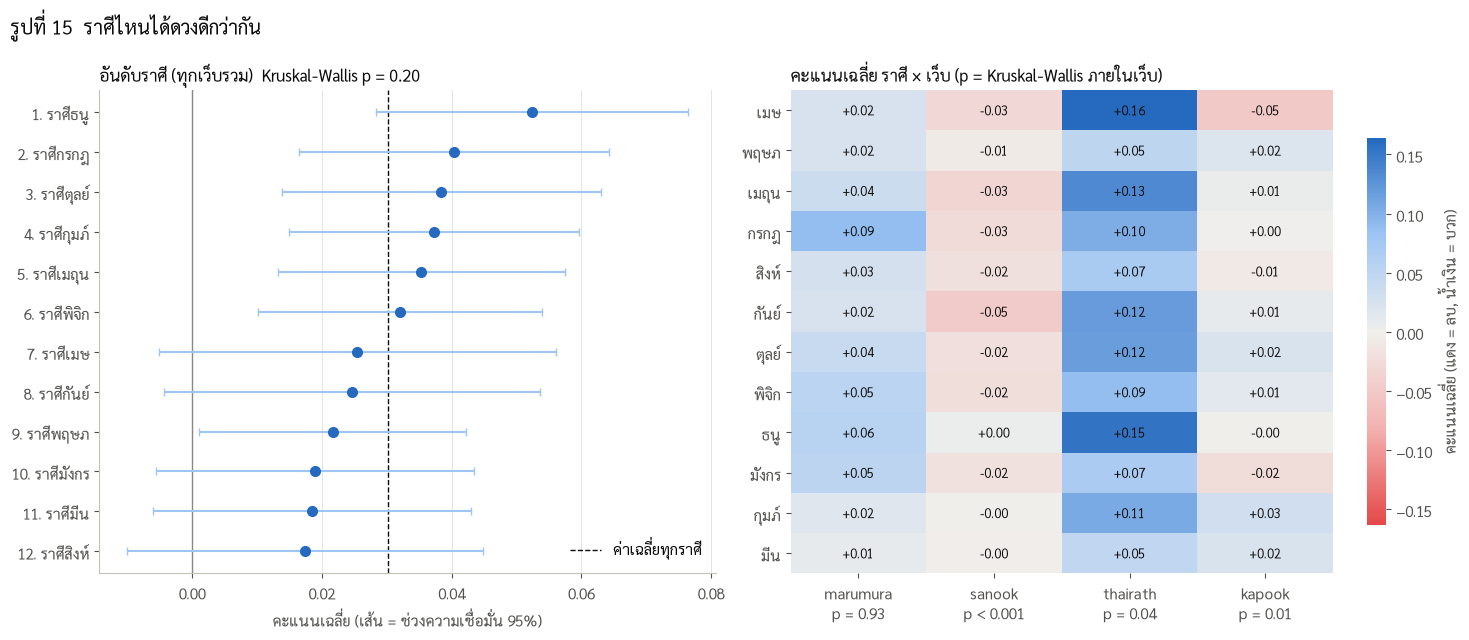

In [7]:
# Figure 15: left = ranking of signs (mean score, 95% CI); right = sign x site heatmap of the mean score
order = sign_table.sort_values("mean_score").index            # best sign at the top
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [1, 1.1]})
ci = 1.96 * sign_table.loc[order, "sd"] / np.sqrt(sign_table.loc[order, "n"])
y = np.arange(len(order))
ax1.axvline(0, color="#898781", linewidth=1)
ax1.axvline(df["score"].mean(), color="#0b0b0b", linewidth=1, linestyle="--", label="ค่าเฉลี่ยทุกราศี")
ax1.legend(frameon=False, loc="lower right")
ax1.errorbar(sign_table.loc[order, "mean_score"], y, xerr=ci, fmt="o", color="#256abf", ecolor="#9ec5f4",
             capsize=3, markersize=7)
ax1.set_yticks(y, [f"{len(order) - k}. ราศี{SIGN_TH[z]}" for k, z in enumerate(order)])
ax1.set_xlabel("คะแนนเฉลี่ย (เส้น = ช่วงความเชื่อมั่น 95%)")
ax1.grid(axis="y", visible=False)
ax1.set_title(f"อันดับราศี (ทุกเว็บรวม)  Kruskal-Wallis p = {tests['ทุกเว็บรวม']:.2f}", loc="left")

limit = np.nanmax(np.abs(sign_site.values))
im = ax2.imshow(sign_site.values, cmap=DIVERGING, vmin=-limit, vmax=limit, aspect="auto")
ax2.set_xticks(range(len(SITES)), [f"{s}\n" + ("p < 0.001" if tests[s] < 0.001 else f"p = {tests[s]:.2f}") for s in SITES])
ax2.set_yticks(range(12), [SIGN_TH[z] for z in SIGNS])
ax2.grid(False)
for spine in ax2.spines.values():
    spine.set_visible(False)
for i in range(12):
    for j in range(len(SITES)):
        ax2.text(j, i, f"{sign_site.values[i, j]:+.2f}", ha="center", va="center", fontsize=9)
cbar = fig.colorbar(im, ax=ax2, shrink=0.8)
cbar.set_label("คะแนนเฉลี่ย (แดง = ลบ, น้ำเงิน = บวก)")
cbar.outline.set_visible(False)
ax2.set_title("คะแนนเฉลี่ย ราศี × เว็บ (p = Kruskal-Wallis ภายในเว็บ)", loc="left")
fig.suptitle("รูปที่ 15  ราศีไหนได้ดวงดีกว่ากัน", x=0.01, ha="left", fontsize=14)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_sentiment_by_sign.png")
plt.show()

**จากตารางและรูปที่ 15 พบว่า**
- **อันดับราศี (ซ้าย):** ราศีธนูได้คะแนนสูงสุด (+0.052) และราศีสิงห์ต่ำสุด (+0.017) แต่**ช่วงความเชื่อมั่นของทุกราศีซ้อนทับกันเกือบทั้งหมด** และ Kruskal-Wallis p = 0.20 แปลว่า**อันดับนี้เกิดจากความบังเอิญ** ไม่ได้มีราศีไหนดวงดีกว่าจริง
- **ราศีอธิบายความแปรปรวนของคะแนนได้แค่ 0.7% ส่วนเว็บอธิบายได้ 12.4%** (eta²) คือมากกว่าประมาณ 18 เท่า
- **ภายในแต่ละเว็บ (ขวา):**
  - **marumura:** ไม่ต่าง (p = 0.93)
  - **thairath:** p = 0.04 ไม่ผ่านเกณฑ์ Bonferroni (0.0125) เมื่อทดสอบ 4 เว็บพร้อมกัน แม้ราศีเมษและราศีธนูจะดูบวกกว่า
  - **kapook:** p = 0.011 ผ่านเกณฑ์แบบหวุดหวิด แต่ขนาดผลเล็ก (eta² = 0.07 ขณะที่ถ้าราศีไม่มีผลเลยจะได้ประมาณ 0.035 อยู่แล้ว) และ kapook ใช้การเปิดไพ่ทาโรต์แบบสุ่ม จึงน่าจะเกิดจากไพ่ที่สุ่มได้มากกว่าราศี
  - **sanook:** p < 0.001 (eta² = 0.15) เพราะย่อหน้าดาวประจำราศีที่ใช้ซ้ำ (เห็นใน 03 และ 04) มีน้ำเสียงต่างกันในแต่ละราศี

**ความหมาย:** ไม่มีราศีไหน "ดวงดีกว่า" อย่างสม่ำเสมอ ความต่างของน้ำเสียงมาจาก**เว็บ** ซึ่งตรงกับคำถาม Barnum effect

## 5) ตัวอย่างช่วงที่บวกที่สุดและลบที่สุด (ตรวจด้วยตา)

In [8]:
pd.set_option("display.max_colwidth", 160)
examples = seg.merge(df[["source", "zodiac"]], left_on="row", right_index=True)
pd.concat([examples.nlargest(4, "score"), examples.nsmallest(4, "score")])[["source", "zodiac", "score", "segment"]].round(3)

,source,zodiac,score,segment
1583,marumura,Gemini,0.842,ถือว่าดีมาก แต่ส่วนมากจะยังไม่ได้เปลี่ยนทันทีแต่ได้ข่าวก่อนก็ดีใจแล้ว การเงิน ไม่มีอะไรติดขัด อยากได้อะไรก็จะมีคนจัดการให้ การเดินทาง จะได้ไปแบบไม่ตั้งตัว แ...
1292,marumura,Libra,0.768,ดีจริงๆช่วงนี้ การเงิน มีโชคก้อนโตจากการเจรจา เงินเข้าแบบไม่ตั้งตัวนะ ความรัก เอาเป็นว่าคุณมีให้กับทุกคนที่อยู่รอบๆตัวคุณ แค่ขอคุณก็จะจัดให้ ใครไม่รักคุณก็แ...
1622,marumura,Scorpio,0.736,และยังได้ของถูกใจที่อยากได้มานานอีกด้วยนะครับ มันลดราคาพอดี
1648,marumura,Scorpio,0.732,ไปทางทิศตะวันออกแล้วจะได้เจอเพื่อนใหม่ สังคมใหม่ๆ เป็นอะไรที่ดีในอนาคตมากๆ นะครับ
4137,thairath,Scorpio,-0.933,ซึ่งเป็นปัญหาที่คุณเองก็ไม่คาดคิดว่ามันจะเกิดขึ้น
1287,marumura,Leo,-0.889,ชีวิตช่วงนี้น่าเบื่อมากๆ ทุกอย่างจะวนๆ เหมือนเดิมจนจำได้ว่าจะเกิดอะไรขึ้นอีก แล้วก็วนๆไป วนไปจนหมดสัปดาห์ การงาน อย่าคิดว่าจะเจออะไรง่ายๆ ถ้าเริ่มต้นวันแรกค...
1683,marumura,Pisces,-0.852,สัปดาห์นี้หงุดหงิดง่าย เข้าใจอะไรยากไปหมด คุณจะสับสนกับอารมณ์ตัวเองเป็นที่สุด และก็ไม่พยายามที่จะควบคุมมันจนคนรอบข้างคุณไม่ยากจะเข้าใกล้ การงาน ทุกสิ่งอย่าง...
1396,marumura,Virgo,-0.831,ลองไปยื่นอีกที่แล้วให้คนอื่นมาลองบ้าง การเงิน เรื่องจ่ายออกเป็นเรื่องปกติ แต่ที่ไม่ปกติคือเรื่องเงินเข้า มันจะมีข้อผิดพลาดตลอดสัปดาห์ คนช่วยก็ไม่มี ความรัก ...


## สรุปผล 05 Sentiment (ตอบวัตถุประสงค์ข้อ 3)

1. **โมเดล sentiment สำเร็จรูปใช้กับภาษาดวงตรงๆ ไม่ได้:** ป้ายของโมเดลเป็น neu ถึง 97.7% แต่คะแนน P(pos) − P(neg) ยังเรียงลำดับได้ถูก (AUC 0.94 กับชุดที่คนติดป้าย) จึงใช้คะแนนนี้เป็นตัววัดหลัก
2. **sentiment ต่างกันตามเว็บชัดเจน:** thairath บวกที่สุด (+0.10), marumura บวกเล็กน้อยและกระจายมาก, kapook เป็นกลาง, sanook กลาง/ลบเล็กน้อย ทั้งนี้เว็บอธิบายความแปรปรวนได้ 12.4%
3. **sentiment ไม่ต่างกันตามราศี:** อันดับราศีเกิดจากความบังเอิญ (p = 0.20) ราศีอธิบายความแปรปรวนได้แค่ 0.7% และภายในเว็บก็ไม่ต่างหรือต่างน้อยมาก ยกเว้น sanook ที่มีย่อหน้าประจำราศีใช้ซ้ำ

**เชื่อมกับคำถามวิจัย:** เป็นหลักฐานชิ้นที่ 5 ว่าความต่างมาจาก**ผู้เขียน** ไม่ได้มาจาก**ราศี** แม้แต่เรื่องที่คนสนใจที่สุดอย่าง "สัปดาห์นี้ราศีไหนดวงดี" ก็ขึ้นกับว่าอ่านเว็บไหนมากกว่าเป็นราศีอะไร

**ข้อจำกัด:** (1) โมเดลเทรนจากรีวิวร้านอาหารและโซเชียล ไม่ใช่ข้อความดวง (2) ชุดตรวจสอบเล็ก (40 ช่วง, คนติดป้ายคนเดียว) (3) แต่ละช่วงยาวประมาณ 240 ตัวอักษร จึงมักมีทั้งดีและร้ายปนกันในช่วงเดียว

**รูปที่บันทึกไว้:** `outputs/figures/05_sentiment_by_site.png`, `05_sentiment_by_sign.png`